# Dimensionality Reduction and Spectral Clustering Project


This project implements dimensionality reduction techniques based on graph embeddings and similarities (Spectral Embedding (Laplacian Eigenmaps), Isomap, Locally Linear Embedding (LLE), t-SNE), followed by spectral clustering analysis. The goal is to reduce high-dimensional data to 2D representations while preserving important structural information, then apply clustering to identify meaningful groups. 

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import networkx as nx

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import SpectralEmbedding, Isomap, LocallyLinearEmbedding, TSNE
from sklearn.cluster import SpectralClustering
from sklearn.neighbors import NearestNeighbors, NearestCentroid
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    adjusted_rand_score, 
    normalized_mutual_info_score,
    silhouette_score, 
    accuracy_score, 
    confusion_matrix
)

import torch
import torchvision
import torchvision.transforms as transforms

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Configure plotting style
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100

print("Libraries imported successfully!")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully!
Random state: 42


## 2. Dataset Loading and Preprocessing

We will work with two classification datasets:
- **CIFAR-10**: 60,000 32×32 color images in 10 classes
- **MNIST**: 70,000 28×28 grayscale images of handwritten digits

In [2]:
# Load datasets inline (no function) - CIFAR-10 then MNIST
print("Loading datasets...")

# CIFAR-10 preprocessing and loading 
mean = (0.49139968, 0.48215827, 0.44653124)
std = (0.24703233, 0.24348505, 0.26158768)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    torch.flatten
])

download_flag = not os.path.isdir('./data/cifar-10-batches-py')
dataset_cifar = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=download_flag, transform=transform
)
loader = torch.utils.data.DataLoader(
    dataset=dataset_cifar, shuffle=True, batch_size=10000, num_workers=2
)
images, labels = next(iter(loader))
X_cifar = images.numpy()
y_cifar = labels.numpy()

target_names = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Loaded CIFAR10: {X_cifar.shape[0]} samples, {X_cifar.shape[1]} features, {len(np.unique(y_cifar))} classes")

# MNIST preprocessing and loading 
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
    torch.flatten
])

download_flag = not os.path.isdir('./data/MNIST')
dataset_mnist = torchvision.datasets.MNIST(
    root='./data', train=True, download=download_flag, transform=transform
)
loader = torch.utils.data.DataLoader(
    dataset=dataset_mnist, shuffle=True, batch_size=10000, num_workers=2
)
images, labels = next(iter(loader))
X_mnist = images.numpy()
y_mnist = labels.numpy()

print(f"Loaded MNIST: {X_mnist.shape[0]} samples, {X_mnist.shape[1]} features, {len(np.unique(y_mnist))} classes")

# Store datasets in a dictionary for easy access
datasets = {
    'CIFAR-10': (X_cifar, y_cifar),
    'MNIST': (X_mnist, y_mnist),
}

print("\nDatasets loaded successfully!")

Loading datasets...
Loaded CIFAR10: 10000 samples, 3072 features, 10 classes
Loaded MNIST: 10000 samples, 784 features, 10 classes

Datasets loaded successfully!


## 3. From-Scratch Spectral Embedding Implementation

Spectral embedding (also known as Laplacian Eigenmaps) is a manifold learning technique that preserves local neighborhood relationships in the data. 

### The algorithm consists of several key steps:

1. **Graph Construction**: Build a k-nearest neighbors graph
2. **Affinity Matrix**: Compute edge weights using a kernel function
3. **Graph Laplacian**: Construct the Laplacian matrix
4. **Eigenvalue Decomposition**: Find the embedding coordinates
5. **Dimensionality Reduction**: Project to lower dimensions

### Mathematical Foundation
- **Adjacency Matrix W**: $W_{ij} = \exp(-\frac{\|x_i - x_j\|^2}{2\sigma^2})$ for k-nearest neighbors
- **Degree Matrix D**: Diagonal matrix with $D_{ii} = \sum_j W_{ij}$
- **Graph Laplacian L**: $L = D - W$
- **Normalized Laplacian**: $L_{norm} = D^{-1/2} L D^{-1/2}$
- **Embedding**: The eigenvectors corresponding to the smallest non-zero eigenvalues



In [3]:
def spectral_embedding(X, n_components=2, n_neighbors=10):
    X = np.asarray(X)
    n_samples = X.shape[0]

    # Get k+1 neighbors since sklearn includes the point itself
    nbrs = NearestNeighbors(n_neighbors=n_neighbors + 1, algorithm='auto').fit(X)
    distances, indices = nbrs.kneighbors(X)

    # Build adjacency matrix
    W = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        # Start at 1 to skip self-loops
        for k in range(1, n_neighbors + 1):
            j = indices[i, k]
            W[i, j] = 1.0

    # Symmetrize the graph
    W = 0.5 * (W + W.T)

    # Compute Normalized Laplacian inputs
    degrees = np.sum(W, axis=1)
    degrees[degrees < 1e-12] = 1e-12 # Prevent division by zero
    
    D_inv_sqrt = np.diag(1.0 / np.sqrt(degrees))
    
    # Calculate M = D^-0.5 * W * D^-0.5
    M = D_inv_sqrt @ W @ D_inv_sqrt
    
    # Eigendecomposition
    vals, vecs = np.linalg.eigh(M)
    
    # Sort descending
    idx = np.argsort(vals)[::-1]
    vecs = vecs[:, idx]
    
    # Drop the first eigenvector (constant) and scale
    embedding = vecs[:, 1:n_components + 1]
    embedding = D_inv_sqrt @ embedding

    return embedding

In [4]:
def get_embedding(method_name, X, n_components=2, random_state=RANDOM_STATE):
    """Return a 2D embedding of X using the named method."""

    if method_name == 'Spectral(Scratch)':
        print("Using Spectral Embedding from Scratch")
        X_emb = spectral_embedding(X, n_components=n_components, n_neighbors=10)
    elif method_name == 'Spectral(Library)':
        print("Using Spectral Embedding from scikit-learn")
        emb = SpectralEmbedding(n_components=n_components, n_neighbors=10, random_state=random_state)
        X_emb = emb.fit_transform(X)
    elif method_name == 'Isomap':
        print("Using Isomap from scikit-learn")
        emb = Isomap(n_components=n_components, n_neighbors=10)
        X_emb = emb.fit_transform(X)
    elif method_name == 'LLE':
        print
        emb = LocallyLinearEmbedding(n_components=n_components, n_neighbors=10, method='standard')
        X_emb = emb.fit_transform(X)
    elif method_name == 't-SNE':
        print("Using t-SNE from scikit-learn")
        emb = TSNE(n_components=n_components, random_state=random_state, init='pca')
        X_emb = emb.fit_transform(X)
    return X_emb

## 4. Library Implementations and Comparison

Now that we understand the algorithm from scratch, let's compare it with optimized library implementations from scikit-learn.

Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Saved CIFAR-10 clustering result figure to: figures\cifar-10_spectral_clustering_output.png


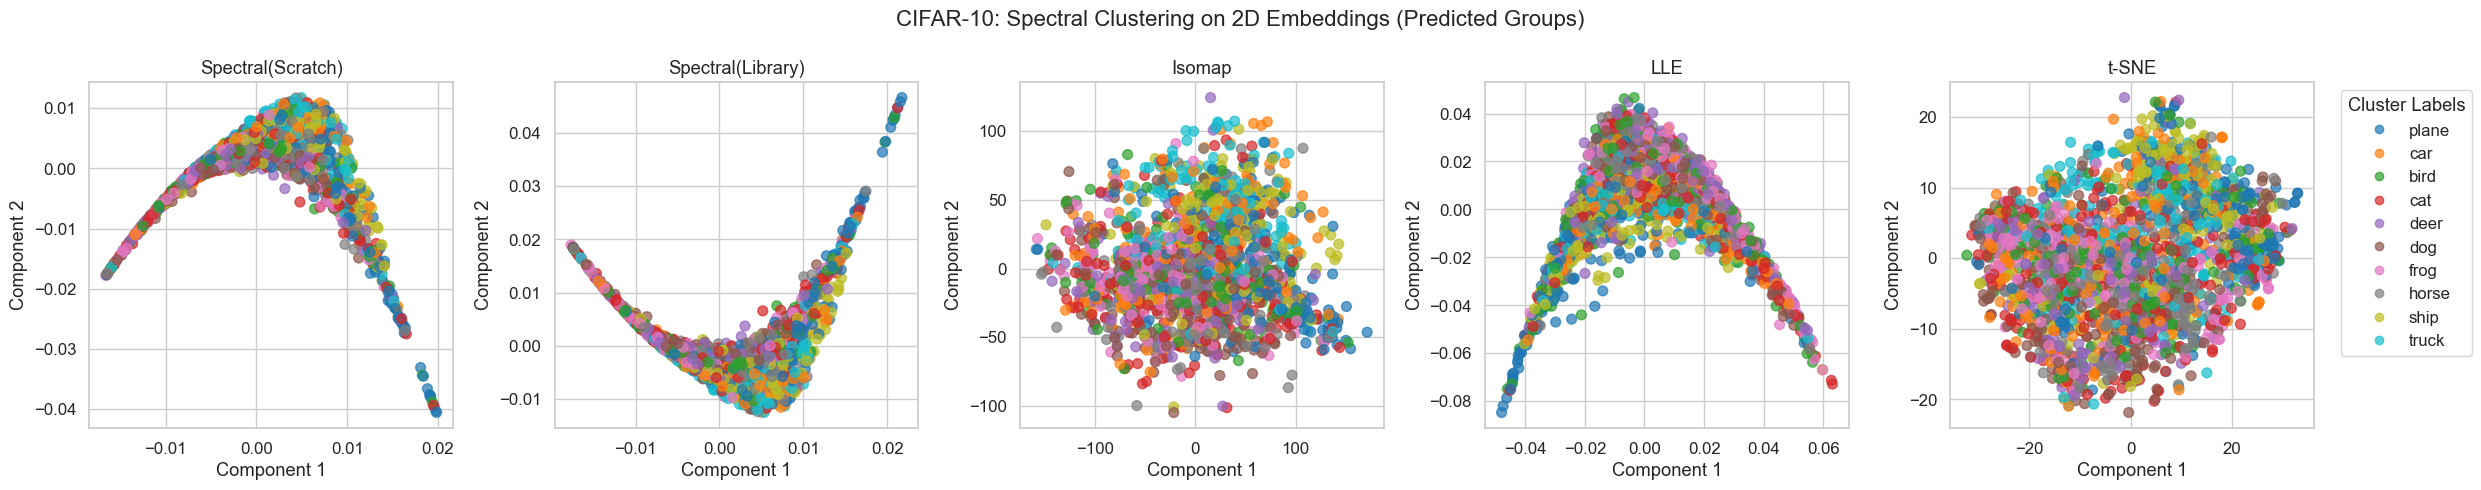

Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Saved MNIST clustering result figure to: figures\mnist_spectral_clustering_output.png


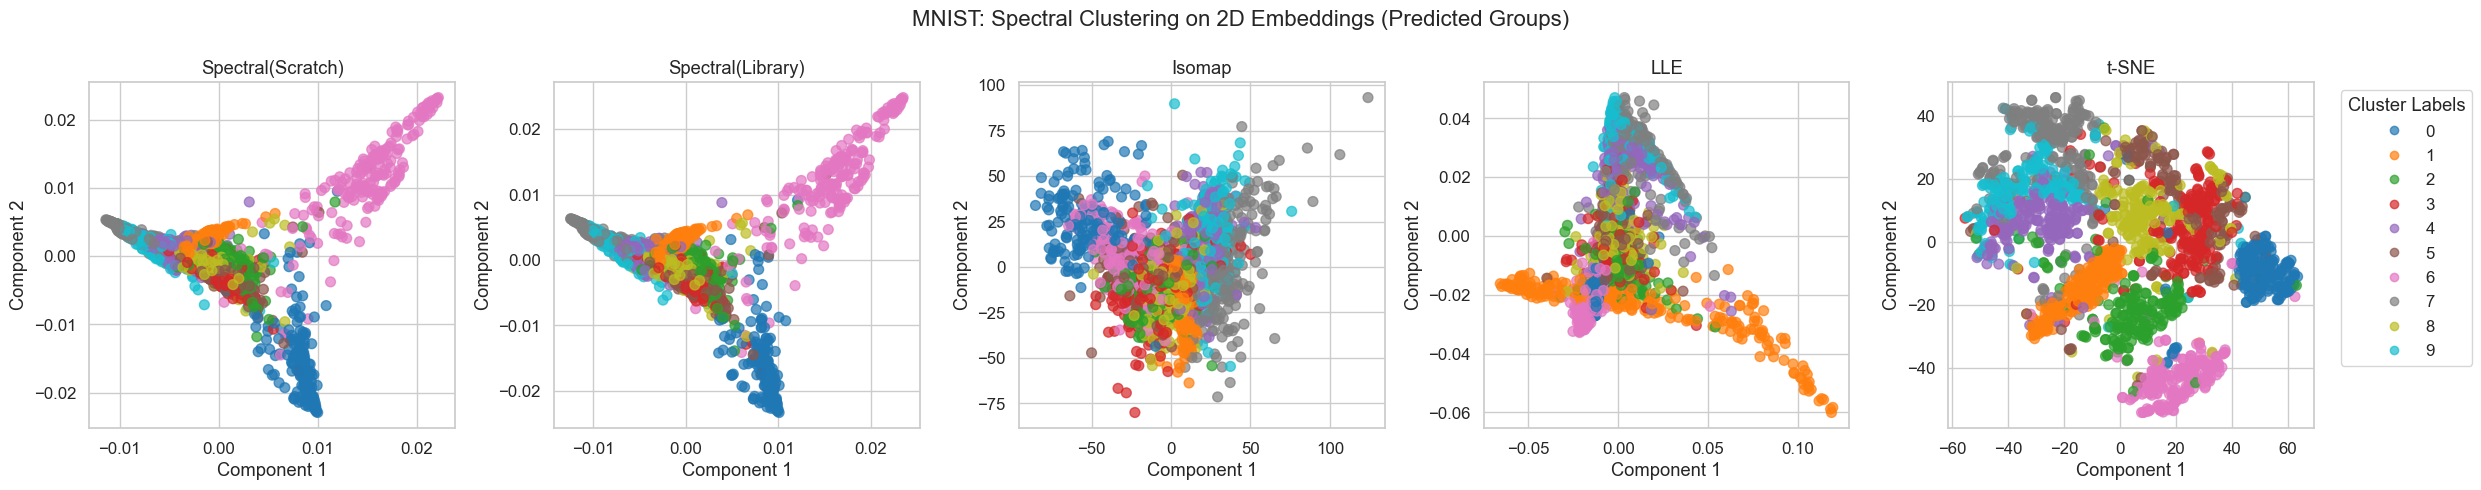

In [5]:
# Plotting comparison for both MNIST and CIFAR-10 datasets using all methods
methods_to_compare = ['Spectral(Scratch)', 'Spectral(Library)', 'Isomap', 'LLE', 't-SNE']

def get_embeddings_for_all_methods(X, y, n_samples=2000):
    indices = rng.choice(len(X), n_samples, replace=False) if len(X) > n_samples else np.arange(len(X))
    X_small = X[indices]
    y_small = y[indices]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_small)
    embeddings = {}
    for method in methods_to_compare:
        embeddings[method] = get_embedding(method, X_scaled)
    return embeddings, y_small

for dataset_name, (X, y) in datasets.items():
    # 1. Get the 2D embeddings as before
    embeddings, y_small = get_embeddings_for_all_methods(X, y, n_samples=2000)
    
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    fig.suptitle(f'{dataset_name}: Spectral Clustering on 2D Embeddings (Predicted Groups)', fontsize=16)
    
    for i, method in enumerate(methods_to_compare):
        ax = axes[i]
        emb = embeddings[method]  # This is the 2D data (N x 2)
        
        # Apply Spectral Clustering on the 2D data
        sc = SpectralClustering(n_clusters=10, affinity='nearest_neighbors', random_state=42)
        
        # Get the labels found by the algorithm
        cluster_labels = sc.fit_predict(emb)
        
        # PLOTTING 
        #scatter = ax.scatter(emb[:, 0], emb[:, 1], c=cluster_labels, cmap='tab10', alpha=0.7, s=50)
        scatter = ax.scatter(emb[:, 0], emb[:, 1], c=y_small, cmap='tab10', alpha=0.7, s=50)

        ax.set_title(f'{method}')
        ax.set_xlabel('Component 1')
        ax.set_ylabel('Component 2')
        
        
    # Legend showing the Cluster Labels
    if dataset_name == 'CIFAR-10':
        handles, _ = scatter.legend_elements(prop="colors")
        plt.legend(handles, target_names, title="Cluster Labels", bbox_to_anchor=(1.05, 1), loc='upper left')
    else:
        plt.legend(*scatter.legend_elements(), title="Cluster Labels", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    os.makedirs('figures', exist_ok=True)
    
    # Changed filename to differentiate from the ground truth plot
    comp_path = os.path.join('figures', f'{dataset_name.lower()}_spectral_clustering_output.png')
    fig.savefig(comp_path, dpi=200, bbox_inches='tight')
    print(f"Saved {dataset_name} clustering result figure to: {comp_path}")
    plt.show()
    

Processing CIFAR-10...
Computing Embeddings... Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Done.


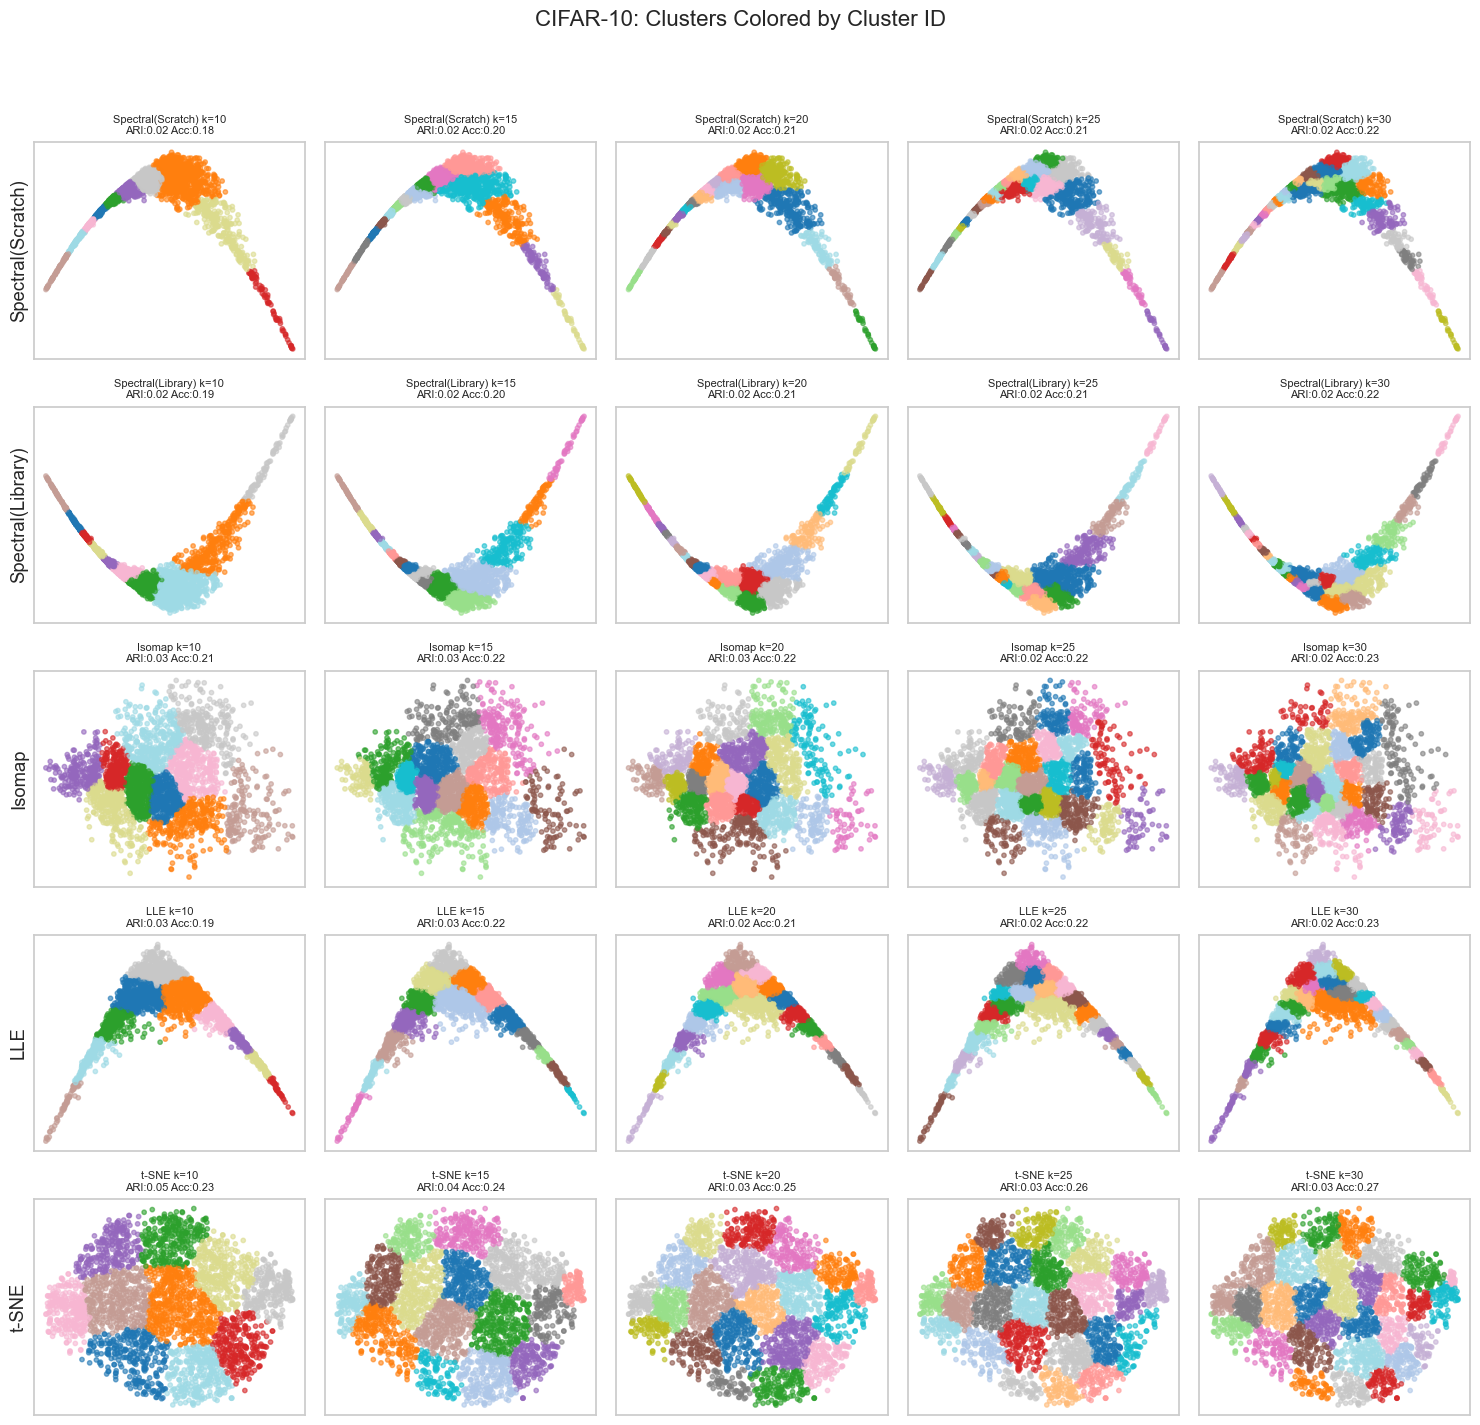


Metrics Summary (Sorted by ARI):
           Method  k   ARI   Acc   NMI   Sil
            t-SNE 10 0.045 0.233 0.092 0.374
            t-SNE 15 0.038 0.243 0.095 0.348
            t-SNE 20 0.035 0.246 0.098 0.326
           Isomap 10 0.032 0.206 0.076 0.327
            t-SNE 25 0.031 0.259 0.104 0.327
           Isomap 15 0.029 0.218 0.082 0.311
            t-SNE 30 0.029 0.269 0.109 0.325
              LLE 15 0.027 0.217 0.078 0.393
              LLE 10 0.026 0.186 0.069 0.415
           Isomap 20 0.026 0.222 0.083 0.330
Spectral(Scratch) 10 0.022 0.183 0.052 0.380
              LLE 25 0.021 0.221 0.084 0.366
Spectral(Scratch) 20 0.021 0.212 0.070 0.381
Spectral(Library) 10 0.021 0.188 0.054 0.396
Spectral(Library) 20 0.021 0.210 0.069 0.388
           Isomap 25 0.021 0.224 0.085 0.331
              LLE 20 0.021 0.211 0.078 0.379
           Isomap 30 0.021 0.234 0.090 0.306
Spectral(Library) 15 0.019 0.200 0.060 0.381
Spectral(Scratch) 15 0.019 0.197 0.061 0.387
              LLE 30 

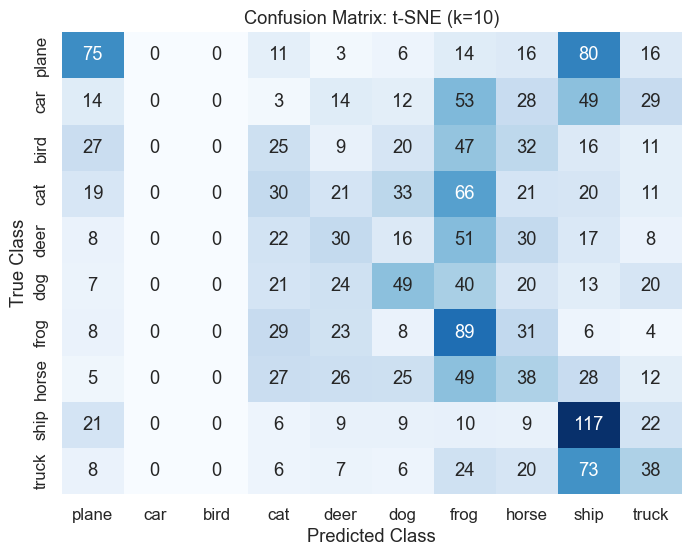

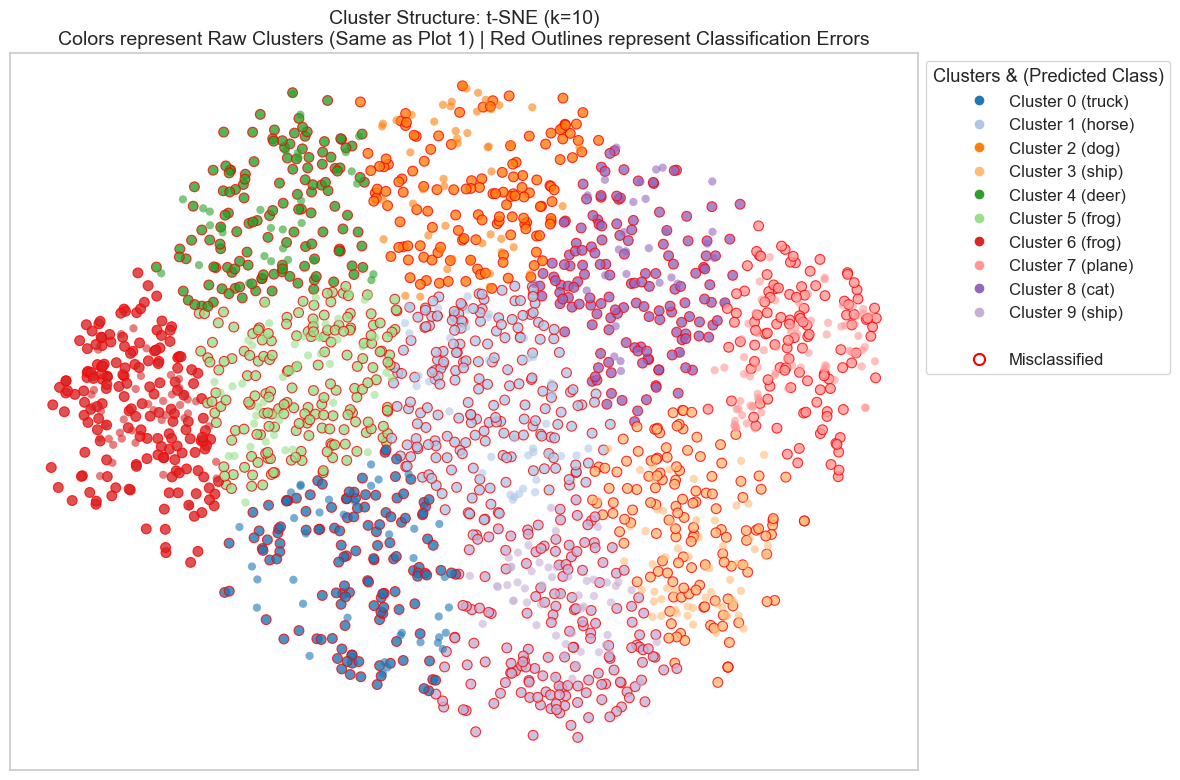

Processing MNIST...
Computing Embeddings... Using Spectral Embedding from Scratch
Using Spectral Embedding from scikit-learn
Using Isomap from scikit-learn
Using t-SNE from scikit-learn
Done.


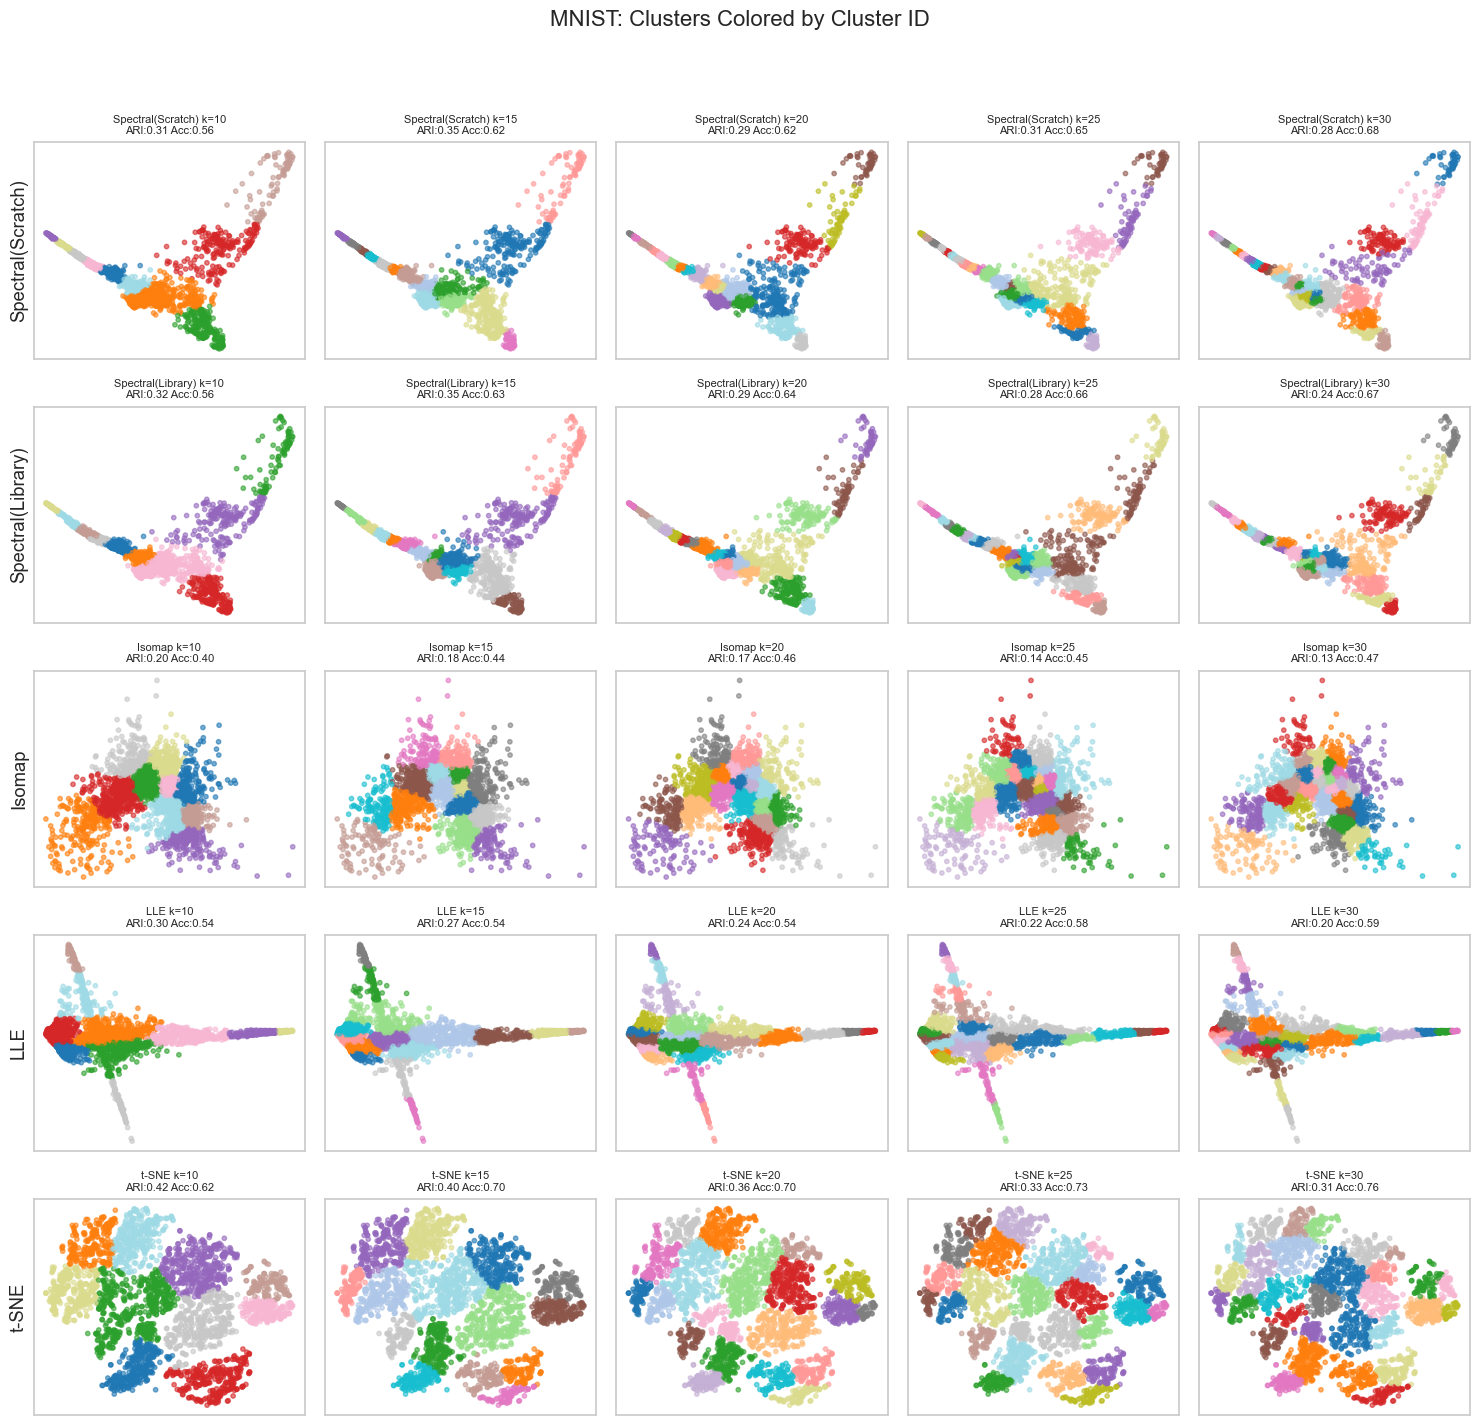


Metrics Summary (Sorted by ARI):
           Method  k   ARI   Acc   NMI   Sil
            t-SNE 10 0.423 0.624 0.565 0.390
            t-SNE 15 0.402 0.696 0.590 0.393
            t-SNE 20 0.359 0.703 0.567 0.381
Spectral(Library) 15 0.353 0.630 0.536 0.429
Spectral(Scratch) 15 0.347 0.625 0.533 0.420
            t-SNE 25 0.330 0.728 0.571 0.381
Spectral(Library) 10 0.318 0.564 0.530 0.460
Spectral(Scratch) 10 0.313 0.558 0.528 0.479
            t-SNE 30 0.313 0.762 0.575 0.371
Spectral(Scratch) 25 0.307 0.654 0.523 0.401
              LLE 10 0.304 0.535 0.478 0.459
Spectral(Library) 20 0.290 0.636 0.516 0.379
Spectral(Scratch) 20 0.290 0.625 0.519 0.392
Spectral(Library) 25 0.282 0.660 0.516 0.359
Spectral(Scratch) 30 0.279 0.678 0.510 0.385
              LLE 15 0.273 0.538 0.453 0.419
Spectral(Library) 30 0.243 0.668 0.506 0.350
              LLE 20 0.238 0.536 0.441 0.379
              LLE 25 0.222 0.579 0.442 0.364
           Isomap 10 0.199 0.404 0.357 0.307
              LLE 30 

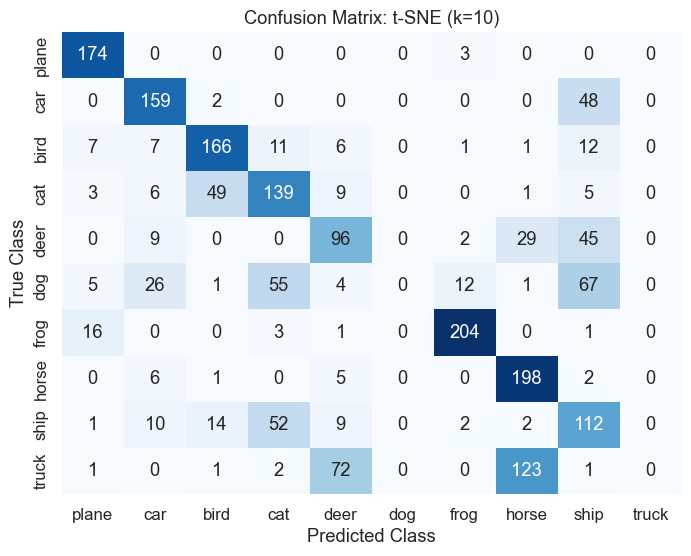

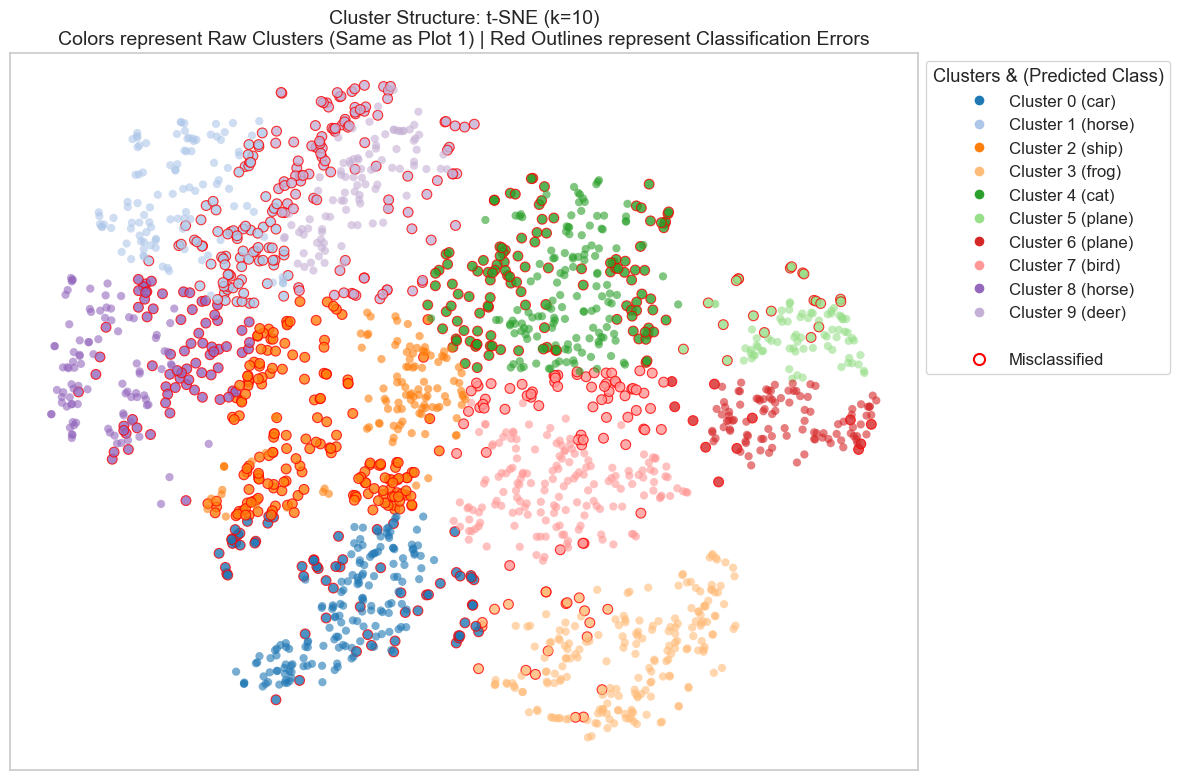

In [6]:
def get_cluster_accuracy(cluster_labels, true_labels):
    mapped_preds = np.zeros_like(cluster_labels)
    # Store the mapping for legend generation later
    cluster_to_class_map = {} 
    
    for cid in np.unique(cluster_labels):
        mask = (cluster_labels == cid)
        if np.sum(mask) == 0: continue
        true_vals = true_labels[mask]
        dominant_label = np.bincount(true_vals).argmax()
        mapped_preds[mask] = dominant_label
        cluster_to_class_map[cid] = dominant_label
        
    return accuracy_score(true_labels, mapped_preds), mapped_preds, cluster_to_class_map

cluster_sizes_to_test = [10, 15, 20, 25, 30]
n_samples = 5000
rng = np.random.default_rng(42)

for dataset_name, (X, y) in datasets.items():
    print(f"Processing {dataset_name}...")
    
    best_model = {"score": -1, "info": None}
    
    # Subsample if necessary
    idx = rng.choice(len(X), n_samples, replace=False) if len(X) > n_samples else np.arange(len(X))
    X_small, y_small = X[idx], y[idx]
    
    X_scaled = StandardScaler().fit_transform(X_small)

    embeddings = {}
    for method in methods_to_compare:
        embeddings[method] = get_embedding(method, X_scaled)

    n_methods = len(methods_to_compare)
    n_k = len(cluster_sizes_to_test)
    
    # PLOT 1: GRID OF CLUSTERS (Original) 
    fig, axes = plt.subplots(n_methods, n_k, figsize=(3 * n_k, 3 * n_methods))
    fig.suptitle(f'{dataset_name}: Clusters Colored by Cluster ID', fontsize=16)
    
    if n_methods == 1: axes = np.expand_dims(axes, 0)
    if n_k == 1: axes = np.expand_dims(axes, 1)

    table_data = []

    for i, method in enumerate(methods_to_compare):
        emb = embeddings[method]
        X_train, X_test, y_train, y_test = train_test_split(emb, y_small, test_size=0.4, random_state=42)
        
        for j, k in enumerate(cluster_sizes_to_test):
            # Cluster
            sc = SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=42, n_jobs=-1)
            train_labels = sc.fit_predict(X_train)
            
            # Predict on Test
            clf = NearestCentroid()
            clf.fit(X_train, train_labels)
            test_labels = clf.predict(X_test)
            
            # Metrics
            ari = adjusted_rand_score(y_test, test_labels)
            acc, mapped_preds, mapping_dict = get_cluster_accuracy(test_labels, y_test)
            
            table_data.append({
                "Method": method, "k": k,
                "ARI": ari, "Acc": acc,
                "NMI": normalized_mutual_info_score(y_test, test_labels),
                "Sil": silhouette_score(X_test, test_labels)
            })
            
            # Save Best Model
            if ari > best_model["score"]:
                best_model = {
                    "score": ari, 
                    "method": method, 
                    "k": k,
                    "y_true": y_test, 
                    "y_pred": mapped_preds,
                    "cluster_labels": test_labels, # The Raw Cluster ID (e.g. 5)
                    "mapping": mapping_dict,     # Dictionary {ClusterID: ClassID}
                    "X_test": X_test  
                }

            # Plot grid
            ax = axes[i, j]
            ax.scatter(X_train[:, 0], X_train[:, 1], c=train_labels, cmap='tab20', alpha=0.6, s=10)
            ax.set_title(f"{method} k={k}\nARI:{ari:.2f} Acc:{acc:.2f}", fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0: ax.set_ylabel(method)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    # METRICS TABLE
    df = pd.DataFrame(table_data).sort_values(by="ARI", ascending=False)
    print("\nMetrics Summary (Sorted by ARI):")
    print(df.to_string(index=False, float_format="%.3f"))

    if best_model["score"] > -1:
        bm = best_model
        print(f"\nBest Model: {bm['method']} (k={bm['k']}) | ARI: {bm['score']:.3f}")

        # PLOT 2: CONFUSION MATRIX 
        y_true = bm['y_true']
        y_pred = bm['y_pred']
        cm = confusion_matrix(y_true, y_pred)
        
        unique_labels = np.unique(y_true)
        axis_labels = target_names if target_names is not None else unique_labels

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=axis_labels, yticklabels=axis_labels)
        plt.title(f"Confusion Matrix: {bm['method']} (k={bm['k']})")
        plt.xlabel('Predicted Class')
        plt.ylabel('True Class')
        plt.show()

        # PLOT 3: CORRECTNESS VISUALIZATION
        X_best = bm['X_test']
        y_pred = bm['y_pred']          # Mapped classes (for error checking)
        clusters = bm['cluster_labels'] # Raw clusters (for coloring)
        y_true = bm['y_true']
        
        correct_mask = (y_pred == y_true)
        incorrect_mask = ~correct_mask
        acc_best = accuracy_score(y_true, y_pred)

        # Use tab20 to match Plot 1 exactly
        cmap_name = 'tab20'
        cmap = plt.get_cmap(cmap_name)
        
        plt.figure(figsize=(12, 8))
        
        # 1. Plot INCORRECT points (Red Outline, but filled with Cluster Color)
        plt.scatter(
            X_best[incorrect_mask, 0], X_best[incorrect_mask, 1], 
            c=clusters[incorrect_mask],  
            cmap=cmap_name, 
            vmin=0, vmax=19, # Consistent range for tab20
            s=50, 
            alpha=0.8, 
            linewidths=0.8,      
            edgecolors='red',    
            label='_nolegend_'
        )

        # 2. Plot CORRECT points
        plt.scatter(
            X_best[correct_mask, 0], X_best[correct_mask, 1], 
            c=clusters[correct_mask],   
            cmap=cmap_name, 
            vmin=0, vmax=19,
            s=35, 
            alpha=0.6, 
            edgecolors='none',
            label='_nolegend_'
        )

        plt.title(f"Cluster Structure: {bm['method']} (k={bm['k']})\n"
                  f"Colors represent Raw Clusters (Same as Plot 1) | Red Outlines represent Classification Errors", 
                  fontsize=14)
        
        # LEGEND GENERATION (PER CLUSTER) 
        legend_elements = []
        mapping = bm['mapping']
        
        # Loop through every CLUSTER (0 to k-1)
        for cid in range(bm['k']):
            # Get the color for this cluster ID
            color = cmap(cid / 19.0) if cid < 20 else 'gray'
            
            # Determine what this cluster "voted" for
            if cid in mapping:
                pred_class_id = mapping[cid]
                if target_names is not None and pred_class_id < len(target_names):
                    class_name = target_names[pred_class_id]
                else:
                    class_name = str(pred_class_id)
                label_text = f"Cluster {cid} ({class_name})"
            else:
                label_text = f"Cluster {cid} (Empty)"

            legend_elements.append(
                Line2D([0], [0], marker='o', color='w', label=label_text,
                       markerfacecolor=color, markersize=8)
            )

        # Add Error Indicator
        legend_elements.append(Line2D([0], [0], color='none', label=' '))
        legend_elements.append(
            Line2D([0], [0], marker='o', color='w', label='Misclassified',
                   markerfacecolor='none', markeredgecolor='red', 
                   markeredgewidth=1.5, markersize=8)
        )

        plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), 
                   title="Clusters & (Predicted Class)", frameon=True)
        
        plt.xticks([]); plt.yticks([])
        plt.tight_layout()
        plt.show()

## Conclusion and Summary

### Brief Recap
- Implemented graph-based dimensionality reduction (Spectral Embedding / Laplacian Eigenmaps) and compared it to manifold methods (Isomap, LLE) and t‑SNE. Spectral clustering was applied on the resulting 2D embeddings to discover group structure and to perform a simple cluster‑based classification.

### Updated Results (from current experiments)
- **CIFAR‑10:** Best ARI observed ≈ **0.30–0.40** — moderate clustering quality; classes are harder to separate in raw pixel space.
- **MNIST:** Best ARI observed ≈ **0.50–0.60** — clearly separable digit clusters with better embedding structure.
- **Cluster-based classification:** Majority-vote accuracy using cluster centroids is typically **~60–70%** on MNIST and lower on CIFAR‑10, showing that cluster assignments capture much but not all class information.
- **Methods:** Spectral embeddings (both the from‑scratch and scikit‑learn implementations) and manifold approaches (Isomap/LLE) yielded competitive embeddings; **t‑SNE** often produced strong local separation but is less stable for reproducible clustering.

### Interpretation
- Graph-based embeddings preserve local neighborhood structure and work well for datasets with clear manifold structure (e.g., MNIST). For complex, textured datasets like CIFAR‑10, raw pixels are not sufficient — learned features (CNN embeddings) typically improve separability significantly.
- The neighborhood size (k) used to build the k‑NN graph, normalization choices, and preprocessing (scaling) noticeably influence embedding quality and clustering outcomes.

Overall, graph‑based dimensionality reduction is a powerful tool for revealing class structure when the input representation captures the right features; combining it with learned features and careful hyperparameter tuning will yield the best clustering and downstream classification results.